In [1]:
# IMPORT REQUIRED LIBRARIES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import re
import string
import warnings

warnings.filterwarnings("ignore")

# NLP
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

# Machine Learning
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

In [2]:
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [3]:
df = pd.read_csv("news_articles.csv")

In [4]:
df.head()

,author,published,title,text,language,site_url,main_img_url,type,label,title_without_stopwords,text_without_stopwords,hasImage
0,Barracuda Brigade,2016-10-26T21:41:00.000+03:00,muslims busted they stole millions in govt ben...,print they should pay all the back all the mon...,english,100percentfedup.com,http://bb4sp.com/wp-content/uploads/2016/10/Fu...,bias,Real,muslims busted stole millions govt benefits,print pay back money plus interest entire fami...,1.0
1,reasoning with facts,2016-10-29T08:47:11.259+03:00,re why did attorney general loretta lynch plea...,why did attorney general loretta lynch plead t...,english,100percentfedup.com,http://bb4sp.com/wp-content/uploads/2016/10/Fu...,bias,Real,attorney general loretta lynch plead fifth,attorney general loretta lynch plead fifth bar...,1.0
2,Barracuda Brigade,2016-10-31T01:41:49.479+02:00,breaking weiner cooperating with fbi on hillar...,red state \nfox news sunday reported this mor...,english,100percentfedup.com,http://bb4sp.com/wp-content/uploads/2016/10/Fu...,bias,Real,breaking weiner cooperating fbi hillary email ...,red state fox news sunday reported morning ant...,1.0
3,Fed Up,2016-11-01T05:22:00.000+02:00,pin drop speech by father of daughter kidnappe...,email kayla mueller was a prisoner and torture...,english,100percentfedup.com,http://100percentfedup.com/wp-content/uploads/...,bias,Real,pin drop speech father daughter kidnapped kill...,email kayla mueller prisoner tortured isis cha...,1.0
4,Fed Up,2016-11-01T21:56:00.000+02:00,fantastic trumps point plan to reform healthc...,email healthcare reform to make america great ...,english,100percentfedup.com,http://100percentfedup.com/wp-content/uploads/...,bias,Real,fantastic trumps point plan reform healthcare ...,email healthcare reform make america great sin...,1.0


In [5]:
df.shape

(2096, 12)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2096 entries, 0 to 2095
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   author                   2096 non-null   object 
 1   published                2096 non-null   object 
 2   title                    2096 non-null   object 
 3   text                     2050 non-null   object 
 4   language                 2095 non-null   object 
 5   site_url                 2095 non-null   object 
 6   main_img_url             2095 non-null   object 
 7   type                     2095 non-null   object 
 8   label                    2095 non-null   object 
 9   title_without_stopwords  2094 non-null   object 
 10  text_without_stopwords   2046 non-null   object 
 11  hasImage                 2095 non-null   float64
dtypes: float64(1), object(11)
memory usage: 196.6+ KB


In [7]:
df.describe()

,hasImage
count,2095.000000
mean,0.777088
std,0.416299
min,0.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,1.000000


In [8]:
df.isnull().sum()

author                      0
published                   0
title                       0
text                       46
language                    1
site_url                    1
main_img_url                1
type                        1
label                       1
title_without_stopwords     2
text_without_stopwords     50
hasImage                    1
dtype: int64

In [9]:
# Remove rows where the target label is missing
df = df.dropna(subset=["label"]).copy()

In [10]:
# Remove rows where the main article text is missing
df = df.dropna(subset=["text"]).copy()

In [11]:
# Reset index after removing incomplete records
df = df.reset_index(drop=True)

In [12]:
df.duplicated().sum()

np.int64(10)

In [13]:
df.drop_duplicates(inplace=True)

In [14]:
df.shape

(2040, 12)

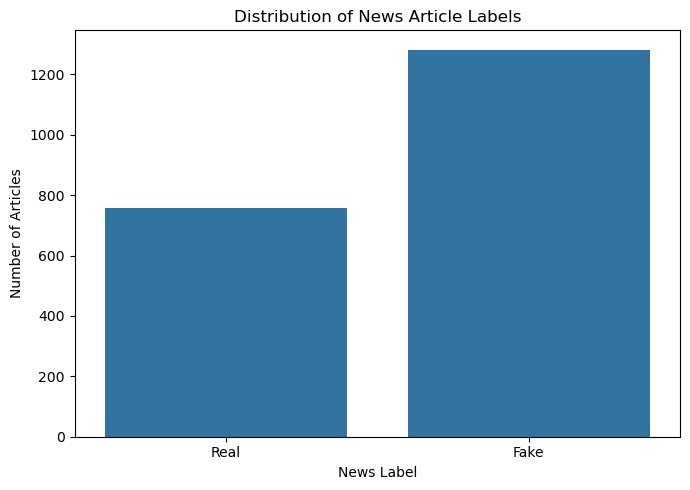

In [15]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="label"
)

plt.title("Distribution of News Article Labels")
plt.xlabel("News Label")
plt.ylabel("Number of Articles")
plt.tight_layout()
plt.show()

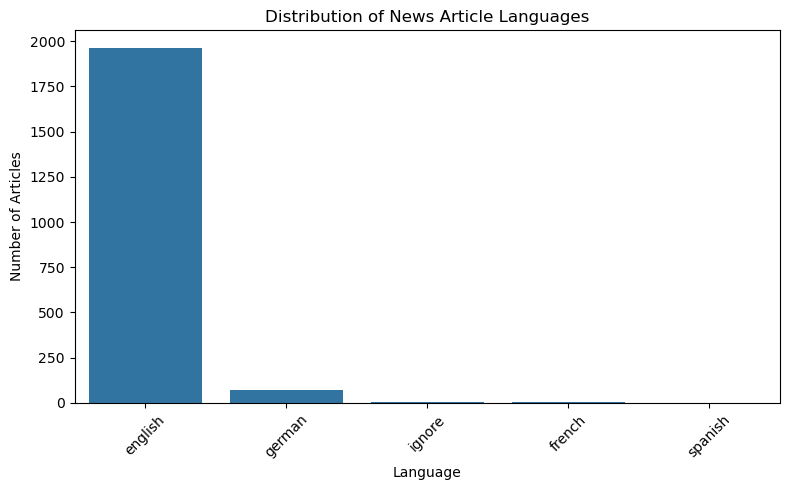

In [16]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="language",
    order=df["language"].value_counts().index
)

plt.title("Distribution of News Article Languages")
plt.xlabel("Language")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

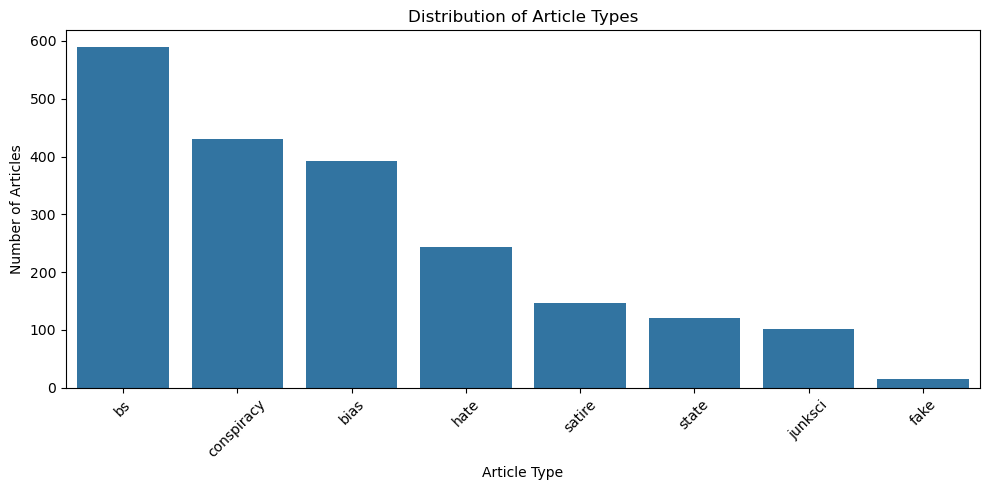

In [17]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="type",
    order=df["type"].value_counts().index
)

plt.title("Distribution of Article Types")
plt.xlabel("Article Type")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [18]:
# Combine title and article body
df["combined_text"] = (
    df["title"] + " " + df["text"]
)

# Remove records where both title and text are empty
df = df[
    df["combined_text"].str.strip().str.len() > 0
].copy()

In [19]:
label_encoder = LabelEncoder()
df["target"] = label_encoder.fit_transform(df["label"])

# NLP

In [20]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()
print("Number of English stopwords:", len(stop_words))

Number of English stopwords: 198


## TEXT PREPROCESSING FUNCTION

In [21]:
def preprocess_text(text):
    """
    Cleans and normalises news article text.

    Steps:
    1. Lowercase conversion
    2. Remove URLs
    3. Remove HTML tags
    4. Remove punctuation
    5. Remove numbers
    6. Tokenisation
    7. Stop-word removal
    8. Lemmatisation
    9. Text normalisation
    """

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", " ", text)

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Remove punctuation
    text = text.translate(
        str.maketrans("", "", string.punctuation)
    )

    # Remove numbers
    text = re.sub(r"\d+", " ", text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    # Tokenisation
    tokens = word_tokenize(text)

    # Remove stopwords and short tokens
    tokens = [
        word for word in tokens
        if word not in stop_words
        and len(word) > 2
        and word.isalpha()
    ]

    # Lemmatisation
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    # Return cleaned text
    return " ".join(tokens)

## APPLY NLP PREPROCESSING

In [22]:
df["clean_text"] = df["combined_text"].apply(
    preprocess_text
)

### Analyse text length

In [23]:
df["word_count"] = df["clean_text"].str.split().str.len()
print(df["word_count"].describe())

count    2040.000000
mean      286.301961
std       349.231358
min         2.000000
25%        76.000000
50%       191.000000
75%       361.250000
max      3007.000000
Name: word_count, dtype: float64


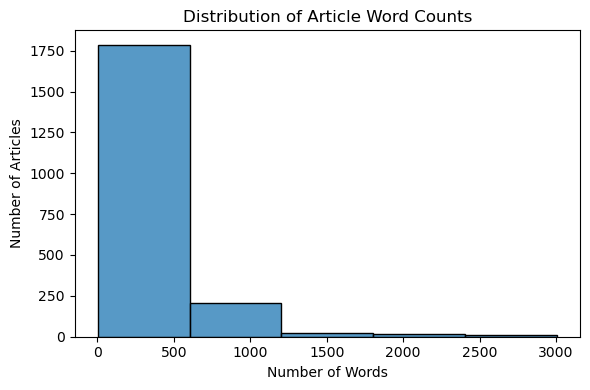

In [24]:
plt.figure(figsize=(6, 4))

sns.histplot(
    data=df,
    x="word_count",
    bins=5
)

plt.title("Distribution of Article Word Counts")
plt.xlabel("Number of Words")
plt.ylabel("Number of Articles")

plt.tight_layout()
plt.show()

In [25]:
X = df["clean_text"]
y = df["target"]

# Train-test split

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# TF-IDF feature extraction

In [27]:
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

In [28]:
# Fit only on training data
X_train_tfidf = tfidf.fit_transform(X_train)

In [29]:
# Transform test data
X_test_tfidf = tfidf.transform(X_test)

In [30]:
# Create Logistic Regression model
lr_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)
# Train the model
lr_model.fit(X_train_tfidf, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,2000
,multi_class,'deprecated'


In [31]:
# Make predictions on test data
lr_pred = lr_model.predict(X_test_tfidf)

In [32]:
# Calculate evaluation metrics
lr_accuracy = accuracy_score(y_test, lr_pred)
lr_precision = precision_score(y_test, lr_pred, zero_division=0)
lr_recall = recall_score(y_test, lr_pred, zero_division=0)
lr_f1 = f1_score(y_test, lr_pred, zero_division=0)

In [33]:
# Probability for ROC-AUC
lr_probability = lr_model.predict_proba(X_test_tfidf)[:, 1]

lr_auc = roc_auc_score(
    y_test,
    lr_probability
)

In [34]:
print("Accuracy :", round(lr_accuracy, 4))
print("Precision:", round(lr_precision, 4))
print("Recall   :", round(lr_recall, 4))
print("F1-Score :", round(lr_f1, 4))
print("ROC-AUC  :", round(lr_auc, 4))

Accuracy : 0.7672
Precision: 0.9524
Recall   : 0.3947
F1-Score : 0.5581
ROC-AUC  : 0.8826


In [35]:
print(
    classification_report(
        y_test,
        lr_pred,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       0.73      0.99      0.84       256
           1       0.95      0.39      0.56       152

    accuracy                           0.77       408
   macro avg       0.84      0.69      0.70       408
weighted avg       0.81      0.77      0.74       408



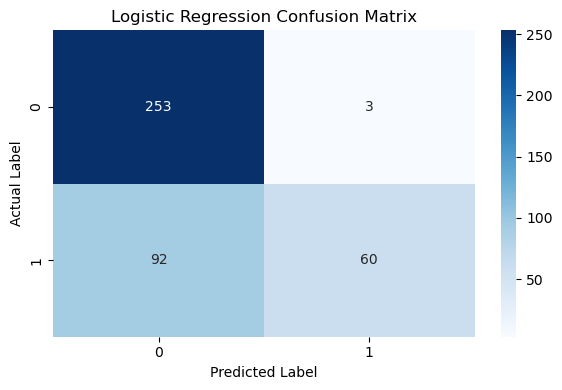

In [36]:
lr_cm = confusion_matrix(
    y_test,
    lr_pred
)

plt.figure(figsize=(6,4))

sns.heatmap(
    lr_cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

# Naïve Bayes

In [37]:
# Create Multinomial Naïve Bayes model
nb_model = MultinomialNB()

# Train the model
nb_model.fit(
    X_train_tfidf,
    y_train
)

,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


In [38]:
# Make predictions
nb_pred = nb_model.predict(
    X_test_tfidf
)

In [39]:
# Calculate metrics
nb_accuracy = accuracy_score(
    y_test,
    nb_pred
)

nb_precision = precision_score(
    y_test,
    nb_pred,
    zero_division=0
)

nb_recall = recall_score(
    y_test,
    nb_pred,
    zero_division=0
)

nb_f1 = f1_score(
    y_test,
    nb_pred,
    zero_division=0
)

In [40]:
# ROC-AUC
nb_probability = nb_model.predict_proba(
    X_test_tfidf
)[:, 1]

nb_auc = roc_auc_score(
    y_test,
    nb_probability
)

In [41]:
print("Accuracy :", round(nb_accuracy, 4))
print("Precision:", round(nb_precision, 4))
print("Recall   :", round(nb_recall, 4))
print("F1-Score :", round(nb_f1, 4))
print("ROC-AUC  :", round(nb_auc, 4))

Accuracy : 0.7328
Precision: 0.9216
Recall   : 0.3092
F1-Score : 0.4631
ROC-AUC  : 0.8593


In [42]:
print(
    classification_report(
        y_test,
        nb_pred,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       0.71      0.98      0.82       256
           1       0.92      0.31      0.46       152

    accuracy                           0.73       408
   macro avg       0.81      0.65      0.64       408
weighted avg       0.79      0.73      0.69       408



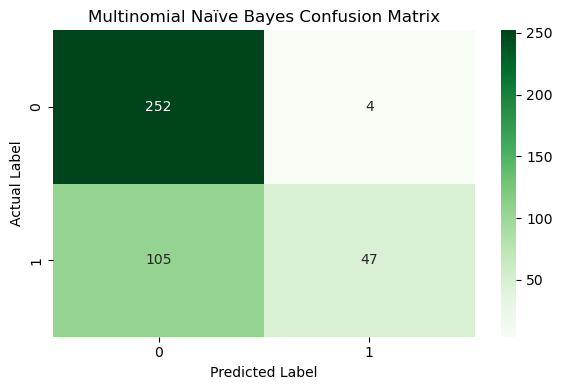

In [43]:
nb_cm = confusion_matrix(
    y_test,
    nb_pred
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    nb_cm,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.title("Multinomial Naïve Bayes Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

# Support Vector Machine

In [44]:
# Create Linear SVM model
svm_model = LinearSVC(
    random_state=42
)

# Train the model
svm_model.fit(
    X_train_tfidf,
    y_train
)

,penalty,'l2'
,loss,'squared_hinge'
,dual,'auto'
,tol,0.0001
,C,1.0
,multi_class,'ovr'
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,verbose,0
,random_state,42


In [45]:
# Make predictions
svm_pred = svm_model.predict(
    X_test_tfidf
)

In [46]:
# Calculate metrics
svm_accuracy = accuracy_score(
    y_test,
    svm_pred
)

svm_precision = precision_score(
    y_test,
    svm_pred,
    zero_division=0
)

svm_recall = recall_score(
    y_test,
    svm_pred,
    zero_division=0
)

svm_f1 = f1_score(
    y_test,
    svm_pred,
    zero_division=0
)

In [47]:
# LinearSVC does not have predict_proba()
# decision_function is used for ROC-AUC
svm_score = svm_model.decision_function(
    X_test_tfidf
)

svm_auc = roc_auc_score(
    y_test,
    svm_score
)

In [48]:
print("Accuracy :", round(svm_accuracy, 4))
print("Precision:", round(svm_precision, 4))
print("Recall   :", round(svm_recall, 4))
print("F1-Score :", round(svm_f1, 4))
print("ROC-AUC  :", round(svm_auc, 4))

Accuracy : 0.8211
Precision: 0.8319
Recall   : 0.6513
F1-Score : 0.7306
ROC-AUC  : 0.8903


In [49]:
print(
    classification_report(
        y_test,
        svm_pred,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       0.82      0.92      0.87       256
           1       0.83      0.65      0.73       152

    accuracy                           0.82       408
   macro avg       0.82      0.79      0.80       408
weighted avg       0.82      0.82      0.82       408



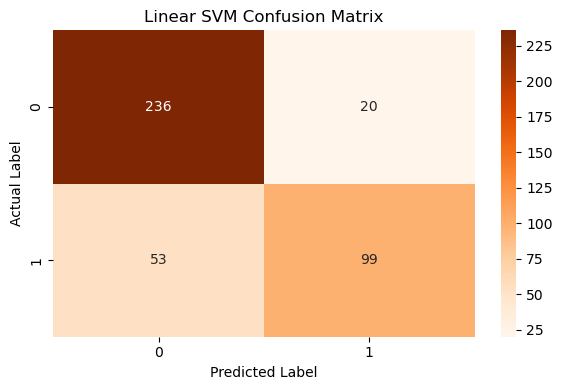

In [50]:
svm_cm = confusion_matrix(
    y_test,
    svm_pred
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    svm_cm,
    annot=True,
    fmt="d",
    cmap="Oranges"
)

plt.title("Linear SVM Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

# Random Forest

In [51]:
# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(
    X_train_tfidf,
    y_train
)

,n_estimators,300
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [52]:
# Make predictions
rf_pred = rf_model.predict(
    X_test_tfidf
)

In [53]:
# Calculate metrics
rf_accuracy = accuracy_score(
    y_test,
    rf_pred
)

rf_precision = precision_score(
    y_test,
    rf_pred,
    zero_division=0
)

rf_recall = recall_score(
    y_test,
    rf_pred,
    zero_division=0
)

rf_f1 = f1_score(
    y_test,
    rf_pred,
    zero_division=0
)

In [54]:
# Probability for ROC-AUC
rf_probability = rf_model.predict_proba(
    X_test_tfidf
)[:, 1]

rf_auc = roc_auc_score(
    y_test,
    rf_probability
)

In [55]:
print("Accuracy :", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1-Score :", round(rf_f1, 4))
print("ROC-AUC  :", round(rf_auc, 4))

Accuracy : 0.7843
Precision: 0.9324
Recall   : 0.4539
F1-Score : 0.6106
ROC-AUC  : 0.8769


In [56]:
print(
    classification_report(
        y_test,
        rf_pred,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       0.75      0.98      0.85       256
           1       0.93      0.45      0.61       152

    accuracy                           0.78       408
   macro avg       0.84      0.72      0.73       408
weighted avg       0.82      0.78      0.76       408



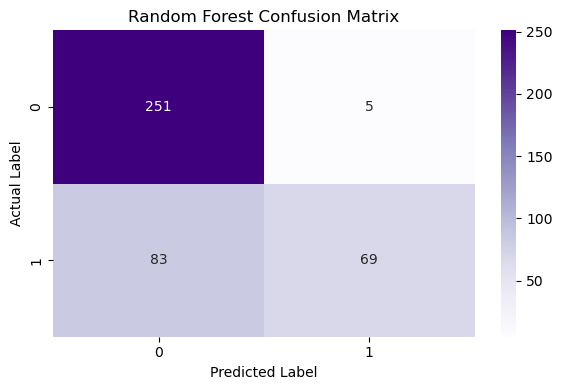

In [57]:
rf_cm = confusion_matrix(
    y_test,
    rf_pred
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Purples"
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

# XGBoost

In [58]:
# Create XGBoost model
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Train the model
xgb_model.fit(
    X_train_tfidf,
    y_train
)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


In [59]:
# Make predictions
xgb_pred = xgb_model.predict(
    X_test_tfidf
)

In [60]:
# Calculate metrics
xgb_accuracy = accuracy_score(
    y_test,
    xgb_pred
)

xgb_precision = precision_score(
    y_test,
    xgb_pred,
    zero_division=0
)

xgb_recall = recall_score(
    y_test,
    xgb_pred,
    zero_division=0
)

xgb_f1 = f1_score(
    y_test,
    xgb_pred,
    zero_division=0
)

In [61]:
# Probability for ROC-AUC
xgb_probability = xgb_model.predict_proba(
    X_test_tfidf
)[:, 1]

xgb_auc = roc_auc_score(
    y_test,
    xgb_probability
)

In [62]:
print("Accuracy :", round(xgb_accuracy, 4))
print("Precision:", round(xgb_precision, 4))
print("Recall   :", round(xgb_recall, 4))
print("F1-Score :", round(xgb_f1, 4))
print("ROC-AUC  :", round(xgb_auc, 4))

Accuracy : 0.8064
Precision: 0.8614
Recall   : 0.5724
F1-Score : 0.6877
ROC-AUC  : 0.8726


In [63]:
print(
    classification_report(
        y_test,
        xgb_pred,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       0.79      0.95      0.86       256
           1       0.86      0.57      0.69       152

    accuracy                           0.81       408
   macro avg       0.82      0.76      0.77       408
weighted avg       0.82      0.81      0.80       408



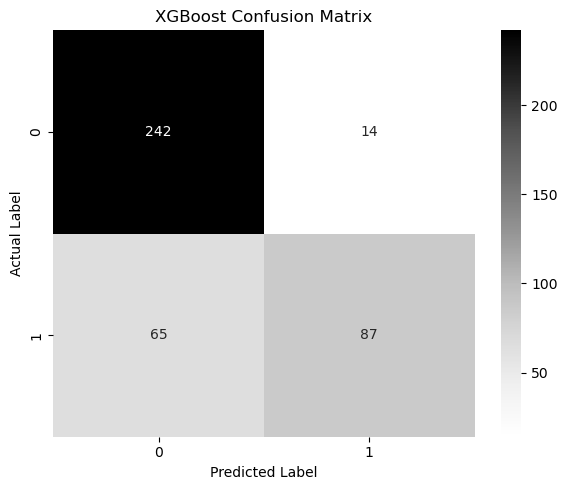

In [64]:
xgb_cm = confusion_matrix(
    y_test,
    xgb_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    xgb_cm,
    annot=True,
    fmt="d",
    cmap="Greys"
)

plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

In [65]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Multinomial Naive Bayes",
        "Linear SVM",
        "Random Forest",
        "XGBoost"
    ],

    "Accuracy": [
        lr_accuracy,
        nb_accuracy,
        svm_accuracy,
        rf_accuracy,
        xgb_accuracy
    ],

    "Precision": [
        lr_precision,
        nb_precision,
        svm_precision,
        rf_precision,
        xgb_precision
    ],

    "Recall": [
        lr_recall,
        nb_recall,
        svm_recall,
        rf_recall,
        xgb_recall
    ],

    "F1-Score": [
        lr_f1,
        nb_f1,
        svm_f1,
        rf_f1,
        xgb_f1
    ],

    "ROC-AUC": [
        lr_auc,
        nb_auc,
        svm_auc,
        rf_auc,
        xgb_auc
    ]
})

# Round values
comparison[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ]
] = comparison[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ]
].round(4)

display(comparison)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.7672,0.9524,0.3947,0.5581,0.8826
1,Multinomial Naive Bayes,0.7328,0.9216,0.3092,0.4631,0.8593
2,Linear SVM,0.8211,0.8319,0.6513,0.7306,0.8903
3,Random Forest,0.7843,0.9324,0.4539,0.6106,0.8769
4,XGBoost,0.8064,0.8614,0.5724,0.6877,0.8726


In [66]:
best_model = comparison.loc[
    comparison["F1-Score"].idxmax()
]

print("Best model based on F1-Score:")
print(best_model["Model"])

print("\nPerformance:")
print(best_model)

Best model based on F1-Score:
Linear SVM

Performance:
Model        Linear SVM
Accuracy         0.8211
Precision        0.8319
Recall           0.6513
F1-Score         0.7306
ROC-AUC          0.8903
Name: 2, dtype: object


# Test the System

In [67]:
def predict_news_svm(article):

    # Step 1: Preprocess the new article
    clean_article = preprocess_text(article)

    # Step 2: Convert the article into TF-IDF features
    article_tfidf = tfidf.transform([clean_article])

    # Step 3: Predict using the trained Linear SVM
    prediction = svm_model.predict(article_tfidf)[0]

    # Step 4: Convert numerical prediction back to original label
    predicted_label = label_encoder.inverse_transform(
        [prediction]
    )[0]

    # Step 5: Obtain SVM decision score
    decision_score = svm_model.decision_function(
        article_tfidf
    )[0]

    # Return the result
    return predicted_label, decision_score

In [68]:
new_article = """
Scientists have announced a major breakthrough in renewable energy
after developing a new technology that could significantly increase
the efficiency of solar panels. Researchers said that the technology
has successfully completed initial laboratory testing and further
testing will be required before commercial production.
"""

In [69]:
prediction, decision_score = predict_news_svm(
    new_article
)

print("SVM Prediction:", prediction)
print("Decision Score:", round(decision_score, 4))

SVM Prediction: Fake
Decision Score: -0.56
